<a href="https://colab.research.google.com/github/Vykhrystenko/ML_FIT_3-9_Vykhrystenko/blob/main/%D0%9B%D0%A012_%D0%92%D0%B8%D1%85%D1%80%D0%B8%D1%81%D1%82%D0%B5%D0%BD%D0%BA%D0%BE_3_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 12
## Рекурентні нейронні мережі (RNN, LSTM). Генерація тексту та підбір гіперпараметрів

**ПІБ студента:** Вихристенко В. О.  

**Група:** 3-9

**Дата:** 27.11.2026

### Мета роботи
Ознайомитися з принципами обробки текстових послідовностей за допомогою **SimpleRNN** та **LSTM**, навчитися підготовлювати текстові дані, будувати й навчати модель передбачення наступного слова, генерувати текст і підбирати гіперпараметри за допомогою **Keras Tuner**.

### Очікуваний результат
- Побудована й навчена модель `Embedding → SimpleRNN → LSTM → Dropout → Dense`.
- Графіки втрат і точності, приклад згенерованого тексту.
- Результат автоматичного підбору гіперпараметрів і порівняння двох моделей.

**Інструкція:** виконуйте кроки послідовно, заповнюйте порожні комірки Python власним кодом. Не видаляйте результати запуску — вони потрібні для перевірки. Рекомендоване середовище: Google Colab або Jupyter Notebook з TensorFlow.

## Частина 1. Створення моделі для передбачення наступного слова

### 1. Імпорт бібліотек
Імпортуйте:
- `numpy` як `np`, `matplotlib.pyplot` як `plt`;
- `Sequential` із `tensorflow.keras.models`;
- `Dense`, `SimpleRNN`, `LSTM`, `Embedding`, `Dropout`;
- `Tokenizer` із `tensorflow.keras.preprocessing.text`;
- `to_categorical` із `tensorflow.keras.utils`.

**Завдання:** переконайтеся, що всі бібліотеки імпортуються без помилок.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Embedding, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import to_categorical

### 2. Вхідний текст для навчання
Створіть рядкову змінну `texts` із наведеним фрагментом вірша. Саме цей текст використовується у вихідному прикладі лабораторної роботи.

```text
Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?..
```

**Завдання:** виведіть початковий текст або перші 100 його символів.

In [2]:
texts = """Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..
Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..
Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?.."""

print(texts[:100])

Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..
Чом вас вітер не розвія


### 3. Попередня обробка та токенізація
1. Видаліть із `texts` можливий символ `\ufeff`.
2. Задайте `maxWordsCount = 1000`.
3. Створіть `Tokenizer` із такими налаштуваннями: `num_words=maxWordsCount`, `lower=True`, `split=' '`, `char_level=False`. Для `filters` використайте набір знаків пунктуації з вихідного прикладу, зокрема `!`, `?`, `.`, `,`, тире та лапки.
4. Навчіть токенізатор на тексті за допомогою `fit_on_texts()`.
5. Виведіть кількість знайдених унікальних слів та кілька відповідностей зі словника `word_index`.

**Підказка:** метод `fit_on_texts()` будує словник відповідностей слів і числових індексів.

In [3]:
texts = texts.replace("\ufeff", "")
maxWordsCount = 1000

filters = '!?.,-—`"\n'
tokenizer = Tokenizer(
    num_words=maxWordsCount,
    filters=filters,
    lower=True,
    split=" ",
    char_level=False,
)
tokenizer.fit_on_texts([texts])

unique_words_count = len(tokenizer.word_index)
print(f"Кількість унікальних слів у словнику: {unique_words_count}")
print("Приклад відповідностей word_index:", list(tokenizer.word_index.items())[:15])

Кількість унікальних слів у словнику: 35
Приклад відповідностей word_index: [('не', 1), ('лихо', 2), ('на', 3), ('чом', 4), ('вас', 5), ('в', 6), ('думи', 7), ('мої', 8), ('як', 9), ('мені', 10), ('з', 11), ('вами', 12), ('нащо', 13), ('стали', 14), ('папері', 15)]


### 4. Формування навчальної вибірки
Перетворіть текст на послідовність цілих чисел методом `texts_to_sequences()` і збережіть числову послідовність у змінній `res` як масив NumPy.

Задайте **`inp_words = 3`**. Сформуйте:
- `X` — послідовності з **трьох** сусідніх слів;
- `Y` — **наступне слово** після кожної послідовності у форматі one-hot (`to_categorical`, `num_classes=maxWordsCount`).

Перевірте розміри `X` і `Y`, виведіть перший приклад та його цільове слово.

**Підказка:** кількість навчальних прикладів дорівнює `len(res) - inp_words`.

In [4]:
seq = tokenizer.texts_to_sequences([texts])[0]
res = np.array(seq, dtype=np.int32)

inp_words = 3
X_list, Y_list = [], []

for i in range(len(res) - inp_words):
  X_list.append(res[i : i + inp_words])
  Y_list.append(res[i + inp_words])

X = np.array(X_list)
Y = to_categorical(Y_list, num_classes=maxWordsCount)

print("Розмір X:", X.shape)
print("Розмір Y:", Y.shape)

first_inp_words = [
    tokenizer.index_word.get(idx, "<UNK>") for idx in X[0]
]
first_target_word = tokenizer.index_word.get(np.argmax(Y[0]), "<UNK>")
print(
    f"Перший приклад (індекси): {X[0]} -> слова: {first_inp_words}"
)
print(
    f"Цільове слово (індекс {np.argmax(Y[0])}): '{first_target_word}'"
)

Розмір X: (49, 3)
Розмір Y: (49, 1000)
Перший приклад (індекси): [7 8 7] -> слова: ['думи', 'мої', 'думи']
Цільове слово (індекс 8): 'мої'


### 5. Побудова рекурентної нейронної мережі
Створіть модель `Sequential` із такою архітектурою (як у вихідному ноутбуці):

1. `Embedding(maxWordsCount, 300, input_length=inp_words)` — векторні представлення слів;
2. `SimpleRNN(128, activation='tanh', return_sequences=True)`;
3. `LSTM(128, activation='tanh')`;
4. `Dropout(0.2)`;
5. `Dense(128, activation='relu')`;
6. `Dense(maxWordsCount, activation='softmax')`.

Збережіть модель у змінній `model`.

**Питання:** чому для `SimpleRNN` необхідний параметр `return_sequences=True`, якщо після нього йде шар `LSTM`?

In [7]:
model = Sequential([
    Embedding(
        input_dim=maxWordsCount, output_dim=300, input_length=inp_words
    ),
    SimpleRNN(128, activation="tanh", return_sequences=True),
    LSTM(128, activation="tanh"),
    Dropout(0.2),
    Dense(128, activation="relu"),
    Dense(maxWordsCount, activation="softmax"),
])

return_sequences=True потрібний, щоб SimpleRNN повертав вихід для кожного кроку послідовності, а не лише для останнього кроку - адже наступний шар LSTM очікує на вхід саме послідовність кроків

### 6. Компіляція та перегляд архітектури
Скомпілюйте `model` із параметрами:
- оптимізатор — `adam`;
- функція втрат — `categorical_crossentropy`;
- метрика — `accuracy`.

Виведіть `model.summary()` і запишіть кількість параметрів моделі.

In [12]:
model.compile(
    optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"]
)

model.summary()
print("Загальна кількість параметрів:", model.count_params())

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 3, 300)         │       300,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 3, 128)         │        54,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1000)           │       129,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 632,008 (2.41 MB)

 Trainable params: 632,008 (2.41 MB)

 Non-trainable params: 0 (0.00 B)

Загальна кількість параметрів: 632008


### 7. Навчання моделі
Навчіть модель на `X` та `Y` із параметрами **`batch_size=32`** і **`epochs=50`**. Збережіть історію навчання у змінну `history`.

**Завдання:** виведіть значення точності та функції втрат для останньої епохи.

In [10]:
history = model.fit(X, Y, batch_size=32, epochs=50, verbose=1)

final_loss = history.history["loss"][-1]
final_acc = history.history["accuracy"][-1]
print(
    f"Остання епоха - loss: {final_loss:.4f}, accuracy: {final_acc:.4f}"
)

Epoch 1/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.5918 - loss: 1.6220
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.5918 - loss: 1.5425
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.5306 - loss: 1.4791
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.6327 - loss: 1.3942 
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.6735 - loss: 1.3474
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.6735 - loss: 1.3243
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.6531 - loss: 1.2266
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.7347 - loss: 1.1772
Epoch 9/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.6735 - loss: 1.1315
Epoch 10/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.7551 - loss: 1.0966
Epoch 11/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.7551 - loss: 1.0336
Epoch 12/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.8571 - loss: 0.9934


### 8. Візуалізація навчання
Використовуючи `history.history`, побудуйте **два графіки поруч**:
- функція втрат `loss` залежно від епохи;
- точність `accuracy` залежно від епохи.

Додайте назви графіків, підписи осей і легенди.

**Короткий аналіз:** як змінювалися `loss` та `accuracy`? Чи достатньо цих графіків, щоб оцінити якість моделі на новому тексті?

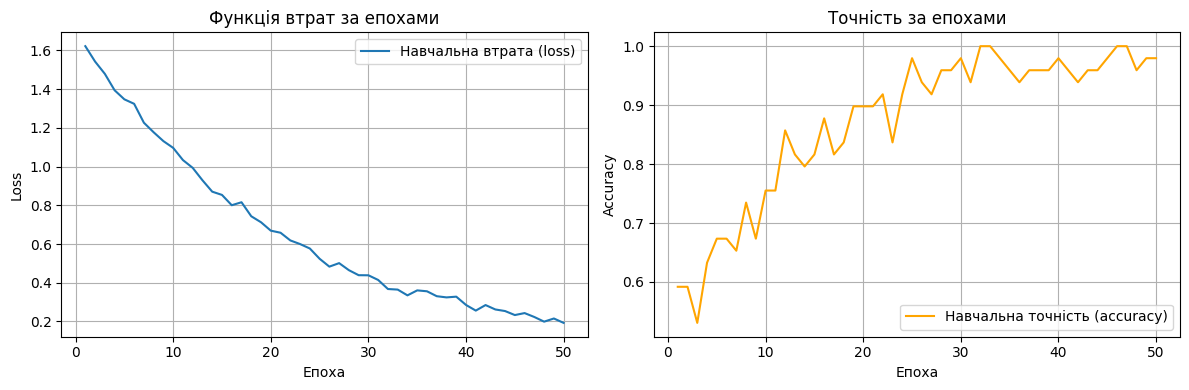

In [13]:
epochs_range = range(1, len(history.history["loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs_range, history.history["loss"], label="Навчальна втрата (loss)")
ax1.set_title("Функція втрат за епохами")
ax1.set_xlabel("Епоха")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True)

ax2.plot(
    epochs_range,
    history.history["accuracy"],
    color="orange",
    label="Навчальна точність (accuracy)",
)
ax2.set_title("Точність за епохами")
ax2.set_xlabel("Епоха")
ax2.set_ylabel("Accuracy")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

У міру збільшення кількості епох loss поступово зменшується, а accuracy зростає - модель запам’ятовує закономірності навчального тексту. Однак цих графіків недостатньо, щоб оцінити якість моделі на новому тексті: немає валідаційної/тестової вибірки, а на такому короткому уривку модель схильна до перенавчання.

### 9. Генерація нового тексту
Реалізуйте функцію **`buildPhrase(texts, str_len=20)`**, яка:
1. Перетворює початковий текст на індекси слів за допомогою `tokenizer`;
2. На кожному кроці передає моделі **останні `inp_words` індексів**;
3. Отримує прогноз `model.predict()`, визначає індекс найбільш імовірного слова через `argmax`;
4. Додає нове слово до послідовності, використовуючи `tokenizer.index_word`;
5. Повертає згенеровану фразу.

Перевірте роботу функції на початковій фразі **`"Думи мої думи"`**, згенеруйте **20 слів**.

**Зверніть увагу:** початкова фраза має містити щонайменше три відомі токенізатору слова. Якщо слово не знайдено, передбачте зрозумілу обробку цього випадку.

In [15]:
def buildPhrase(texts, str_len=20, target_model=model):
  cleaned = texts.lower()
  for ch in filters:
    cleaned = cleaned.replace(ch, " ")
  words = [w for w in cleaned.split() if w]

  seq_indices = []
  for w in words:
    idx = tokenizer.word_index.get(w)
    if idx is not None and idx < maxWordsCount:
      seq_indices.append(idx)
    else:
      print(
          f"Слово '{w}' відсутнє у словнику або поза межами"
          f" maxWordsCount={maxWordsCount} — пропускаємо."
      )

  if len(seq_indices) < inp_words:
    raise ValueError(
        f"Початкова фраза має містити щонайменше {inp_words} відомих"
        " токенізатору слів."
    )

  generated_words = list(words)

  for _ in range(str_len):
    window = np.array([seq_indices[-inp_words:]], dtype=np.int32)
    preds = target_model.predict(window, verbose=0)
    next_idx = int(np.argmax(preds[0]))
    seq_indices.append(next_idx)
    next_word = tokenizer.index_word.get(next_idx, "<UNK>")
    generated_words.append(next_word)

  return " ".join(generated_words)


phrase_model_1 = buildPhrase("Думи мої думи", str_len=20, target_model=model)
print("Згенерований текст (model):\n", phrase_model_1)

Згенерований текст (model):
 думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас вітер не розвіяв в степу як пилину


## Частина 2. Автоматичний підбір гіперпараметрів (Keras Tuner)

### 10. Встановлення та імпорт Keras Tuner
У Google Colab або Jupyter Notebook встановіть (за потреби) пакет `keras-tuner`. Імпортуйте його під псевдонімом `kt`.

**Підказка:** для встановлення пакета в ноутбуці використовуйте `%pip install keras-tuner`.

Повторно створювати `X` та `Y` не потрібно: використайте вибірку з Частини 1.

In [16]:
%pip install -q keras-tuner
import keras_tuner as kt

### 11. Створення функції `build_model(hp)`
Опишіть функцію, яка будує та компілює модель і дає змогу змінювати гіперпараметри:

| Гіперпараметр | Простір пошуку |
|---|---|
| `embedding_dim` | від 128 до 512, крок 64 |
| `rnn_units` | від 64 до 256, крок 64 |
| `lstm_units` | від 64 до 256, крок 64 |
| `dropout_rate` | від 0.1 до 0.5, крок 0.1 |
| `dense_units` | від 64 до 256, крок 64 |
| `optimizer` | `adam` або `rmsprop` |

Збережіть структуру шарів із Частини 1: `Embedding → SimpleRNN → LSTM → Dropout → Dense → Dense`.

**Підказка:** використовуйте `hp.Int()`, `hp.Float()` і `hp.Choice()`; останній шар має `maxWordsCount` нейронів із `softmax`. Функція `build_model(hp)` повинна повертати скомпільовану модель.

In [17]:
def build_model(hp):
  embedding_dim = hp.Int(
      "embedding_dim", min_value=128, max_value=512, step=64
  )
  rnn_units = hp.Int("rnn_units", min_value=64, max_value=256, step=64)
  lstm_units = hp.Int("lstm_units", min_value=64, max_value=256, step=64)
  dropout_rate = hp.Float(
      "dropout_rate", min_value=0.1, max_value=0.5, step=0.1
  )
  dense_units = hp.Int("dense_units", min_value=64, max_value=256, step=64)
  optimizer_choice = hp.Choice("optimizer", values=["adam", "rmsprop"])

  m = Sequential([
      Embedding(
          input_dim=maxWordsCount,
          output_dim=embedding_dim,
          input_length=inp_words,
      ),
      SimpleRNN(rnn_units, activation="tanh", return_sequences=True),
      LSTM(lstm_units, activation="tanh"),
      Dropout(dropout_rate),
      Dense(dense_units, activation="relu"),
      Dense(maxWordsCount, activation="softmax"),
  ])

  m.compile(
      optimizer=optimizer_choice,
      loss="categorical_crossentropy",
      metrics=["accuracy"],
  )
  return m

### 12. Пошук найкращих параметрів
Створіть `kt.RandomSearch` із такими налаштуваннями, як у вихідному прикладі:
- `hypermodel=build_model` (або передайте `build_model` першим аргументом);
- `objective='accuracy'`;
- `max_trials=10`;
- `executions_per_trial=1`;
- `directory='my_tuning'`, `project_name='text_prediction'`.

Запустіть `tuner.search(X, Y, epochs=10, batch_size=32)`.

**Завдання:** отримайте найкращий набір параметрів через `get_best_hyperparameters(num_trials=1)` і виведіть значення всіх шести гіперпараметрів.

**Примітка:** у вихідному прикладі підбір здійснюється за *навчальною* точністю. Це навчальна демонстрація; для об’єктивнішого порівняння зазвичай використовують окрему валідаційну вибірку.

In [18]:
tuner = kt.RandomSearch(
    build_model,
    objective="accuracy",
    max_trials=10,
    executions_per_trial=1,
    directory="my_tuning",
    project_name="text_prediction",
    overwrite=True,
)

tuner.search(X, Y, epochs=10, batch_size=32)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Найкращі гіперпараметри:")
for param in [
    "embedding_dim",
    "rnn_units",
    "lstm_units",
    "dropout_rate",
    "dense_units",
    "optimizer",
]:
  print(f"  {param}: {best_hps.get(param)}")

Trial 10 Complete [00h 00m 04s]
accuracy: 0.1428571492433548

Best accuracy So Far: 0.4285714328289032
Total elapsed time: 00h 00m 49s
Найкращі гіперпараметри:
  embedding_dim: 384
  rnn_units: 192
  lstm_units: 256
  dropout_rate: 0.5
  dense_units: 128
  optimizer: adam


### 13. Навчання моделі з підібраними параметрами
Створіть нову модель із найкращими параметрами (`tuner.hypermodel.build(best_hps)`), збережіть її у змінній `best_model`.

Навчіть `best_model` на `X`, `Y` із `batch_size=32`, `epochs=50`. Історію збережіть у `best_history`.

Виведіть `best_model.summary()`, а також кінцеві значення `loss` і `accuracy`.

In [19]:
best_model = tuner.hypermodel.build(best_hps)
best_history = best_model.fit(X, Y, batch_size=32, epochs=50)

best_model.summary()

best_final_loss = best_history.history["loss"][-1]
best_final_acc = best_history.history["accuracy"][-1]
print(
    f"Кінцеві значення best_model — loss: {best_final_loss:.4f},"
    f" accuracy: {best_final_acc:.4f}"
)

Epoch 1/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.0000e+00 - loss: 6.9096
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.1020 - loss: 6.8944
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.3061 - loss: 6.8783
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.4286 - loss: 6.8544
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.3878 - loss: 6.8144
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.3265 - loss: 6.7452
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.2245 - loss: 6.6145
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.2245 - loss: 6.3041
Epoch 9/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.1429 - loss: 5.6766
Epoch 10/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.1224 - loss: 4.5644
Epoch 11/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.1020 - loss: 3.8750
Epoch 12/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.0816 - loss: 3.80

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 3, 384)         │       384,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 3, 192)         │       110,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 256)            │       459,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1000)           │       129,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,349,370 (12.78 MB)

 Trainable params: 1,116,456 (4.26 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,232,914 (8.52 MB)

Кінцеві значення best_model — loss: 0.9291, accuracy: 0.7755


### 14. Графіки та генерація тексту після підбору
1. Побудуйте графіки `loss` і `accuracy` для `best_history`.
2. Порівняйте фінальні навчальні показники `model` та `best_model` в одному невеликому виводі або таблиці.
3. Згенеруйте **20 слів** із початкової фрази **`"Думи мої думи"`** за допомогою `best_model` (адаптуйте створену функцію або передайте модель їй як аргумент).
4. Порівняйте два згенеровані тексти.

**Зверніть увагу:** на такому невеликому тексті результати можуть бути нестабільними, а висока навчальна точність не означає якісної генерації нових фраз.

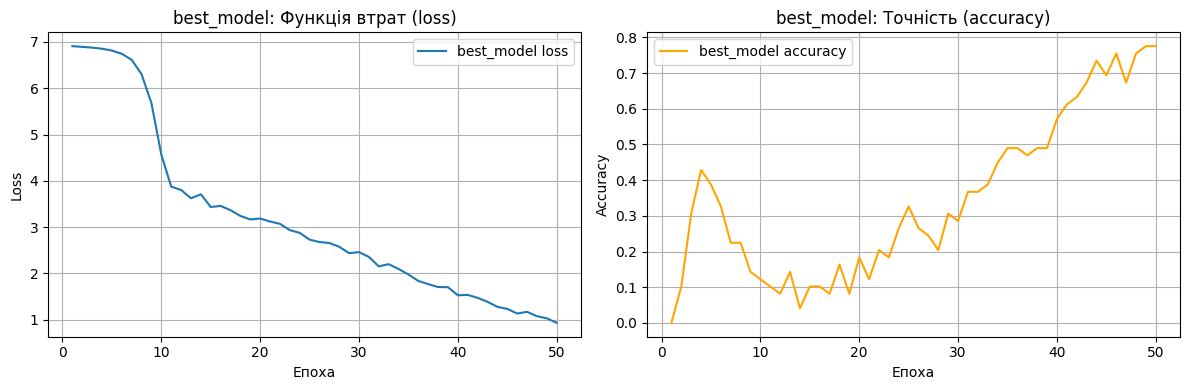

Порівняння фінальних навчальних показників (50 епох):
Модель       | Loss       | Accuracy  
--------------------------------------
model        | 0.1926     | 0.9796    
best_model   | 0.9291     | 0.7755    

Згенерований текст (model):
 думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас вітер не розвіяв в степу як пилину

Згенерований текст (best_model):
 думи мої думи мої лихо мені з вами нащо стали на на сумними рядами рядами вас вітер вітер розвіяв в в як як


In [21]:
epochs_best = range(1, len(best_history.history["loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs_best, best_history.history["loss"], label="best_model loss")
ax1.set_title("best_model: Функція втрат (loss)")
ax1.set_xlabel("Епоха")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True)

ax2.plot(
    epochs_best,
    best_history.history["accuracy"],
    color="orange",
    label="best_model accuracy",
)
ax2.set_title("best_model: Точність (accuracy)")
ax2.set_xlabel("Епоха")
ax2.set_ylabel("Accuracy")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

model_loss = history.history["loss"][-1]
model_acc = history.history["accuracy"][-1]
best_loss = best_history.history["loss"][-1]
best_acc = best_history.history["accuracy"][-1]

print("Порівняння фінальних навчальних показників (50 епох):")
print(f"{'Модель':<12} | {'Loss':<10} | {'Accuracy':<10}")
print("-" * 38)
print(f"{'model':<12} | {model_loss:<10.4f} | {model_acc:<10.4f}")
print(f"{'best_model':<12} | {best_loss:<10.4f} | {best_acc:<10.4f}")

phrase_model_2 = buildPhrase(
    "Думи мої думи", str_len=20, target_model=best_model
)
print("\nЗгенерований текст (model):\n", phrase_model_1)
print("\nЗгенерований текст (best_model):\n", phrase_model_2)

Обидва тексти починаються з однакової початкової фрази та перших згенерованих слів (думи мої думи мої лихо мені з вами нащо стали), після чого розходяться: model відтворює знайомі рядки вірша майже без повторів окремих слів (на папері сумними рядами чом вас вітер не розвіяв в степу як пилину), тоді як best_model починає зациклюватися на окремих словах (на на, рядами рядами, вітер вітер, в в, як як) через меншу навчальну точність (0.7755 проти 0.9796) і малий обсяг навчального тексту.

## Висновки
Напишіть власний висновок **5–8 речень**, спираючись на отримані результати. Висвітліть:

1. Яку роль виконують шари `Embedding`, `SimpleRNN`, `LSTM` та `Dropout`?
2. Яких значень `loss` і `accuracy` досягла початкова модель?
3. Які гіперпараметри обрав Keras Tuner?
4. Чи покращилися навчальні показники після підбору параметрів?
5. Наскільки зв’язним був згенерований текст і чому обсяг корпусу важливий?

**Висновок студента:**

Шар Embedding перетворює індекси слів на вектори, SimpleRNN і LSTM обробляють послідовність слів із урахуванням контексту (з return_sequences=True у SimpleRNN для передачі послідовності кроків у LSTM), а Dropout допомагає зменшувати перенавчання.

Початкова модель model після 50 епох досягла loss = 0.1926 та accuracy = 0.9796.

За допомогою Keras Tuner було обрано гіперпараметри: embedding_dim = 384, rnn_units = 192, lstm_units = 256, dropout_rate = 0.5, dense_units = 128 та оптимізатор adam.

Після навчання протягом 50 епох best_model показала гірші фінальні навчальні показники (loss = 0.9291 та accuracy = 0.7755), ніж базова модель.

Згенеровані 20-слівні фрази були лише частково зв’язними та повторюваними: model відтворила знайомі рядки вірша, тоді як best_model почала зациклюватися на окремих словах. Це показує, що малий обсяг навчального корпусу суттєво обмежує різноманітність і якість генерації тексту навіть за високої навчальної точності.

---

### Що потрібно здати
Заповнений файл `.ipynb` з усім власним кодом, результатами виконання, графіками, двома прикладами згенерованого тексту, знайденими гіперпараметрами та висновками.